# 01 - CWRU Bearing Dataset Exploratory Data Analysis & Validation

## Project: Industrial Fault Detection and Maintenance Prioritization System

### Objective
Perform exploratory data analysis (EDA) and rigorous validation on official vibration acceleration recordings
from the **Case Western Reserve University (CWRU) Bearing Data Center** benchmark.

We investigate a **four-class condition monitoring problem**:
1. **Normal Baseline** (Healthy bearing)
2. **Inner Race Fault** (Single-point defect on rotating inner ring)
3. **Ball Fault** (Single-point defect on rolling element)
4. **Outer Race Fault** (Stationary defect centered at 6:00 in load zone)

### Ground Rules & Data Science Integrity
- **No Synthetic Data**: All signals are genuine experimental measurements downloaded from `engineering.case.edu`.
- **Comparable Conditions**: Matched 1 HP motor load (~1772 RPM), 0.007" EDM defect size, Drive End accelerometer location.
- **Leakage Prevention Awareness**: Slicing continuous time-series into overlapping windows *before* splitting leads to artificial 99.9% test scores. Chronological partitioning or load-isolated testing must be enforced.


## 1. Environment & Library Setup


In [1]:
import os
from pathlib import Path
import scipy.io
import scipy.signal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set matplotlib aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
print('Libraries imported successfully.')


Libraries imported successfully.


## 2. Dataset Manifest & Experimental Specifications

We inspect the dataset manifest created in `data/dataset_manifest.csv` to confirm exact files, labels, and operating parameters.


In [2]:
manifest_path = Path('../data/dataset_manifest.csv')
manifest_df = pd.read_csv(manifest_path)
manifest_df[['file_name', 'class_id', 'class_label', 'fault_diameter_inch', 'motor_load_hp', 'sampling_rate_hz', 'raw_signal_length', 'duration_seconds']]


file_name,class_id,class_label,fault_diameter_inch,motor_load_hp,sampling_rate_hz,raw_signal_length,duration_seconds
98.mat,0,Normal,0.000,1,48000,483903,10.081
106.mat,1,Inner Race Fault,0.007,1,12000,121991,10.166
119.mat,2,Ball Fault,0.007,1,12000,121410,10.118
131.mat,3,Outer Race Fault,0.007,1,12000,122426,10.202


## 3. Data Ingestion, Signal Key Discovery & Integrity Verification

We parse each MATLAB `.mat` file using `scipy.io.loadmat`. Each file uses a specific prefix key structure:
- `X098_DE_time`: Drive End accelerometer (Normal baseline, 48 kHz)
- `X106_DE_time`: Drive End accelerometer (Inner Race defect, 12 kHz)
- `X119_DE_time`: Drive End accelerometer (Ball defect, 12 kHz)
- `X131_DE_time`: Drive End accelerometer (Outer Race defect, 12 kHz)

We verify missing/NaN/infinite values across all recordings.


In [3]:
raw_dir = Path('../data/raw')
files_meta = [
    {'fname': '98.mat', 'key': 'X098_DE_time', 'label': 'Normal', 'fs': 48000, 'class_id': 0},
    {'fname': '106.mat', 'key': 'X106_DE_time', 'label': 'Inner Race Fault', 'fs': 12000, 'class_id': 1},
    {'fname': '119.mat', 'key': 'X119_DE_time', 'label': 'Ball Fault', 'fs': 12000, 'class_id': 2},
    {'fname': '131.mat', 'key': 'X131_DE_time', 'label': 'Outer Race Fault', 'fs': 12000, 'class_id': 3}
]

signals = {}
integrity_checks = []

for meta in files_meta:
    mat = scipy.io.loadmat(str(raw_dir / meta['fname']))
    sig = mat[meta['key']].squeeze().astype(np.float64)
    
    nan_count = int(np.isnan(sig).sum())
    inf_count = int(np.isinf(sig).sum())
    
    # Decimate Normal baseline (48k -> 12k) using scipy.signal.decimate with anti-aliasing filter
    if meta['fs'] == 48000:
        sig_12k = scipy.signal.decimate(sig, 4)
    else:
        sig_12k = sig.copy()
        
    signals[meta['label']] = {'raw': sig, '12k': sig_12k, 'fs': 12000, 'meta': meta}
    integrity_checks.append({
        'File': meta['fname'],
        'Primary Key': meta['key'],
        'Condition': meta['label'],
        'Raw Length': len(sig),
        'NaN Count': nan_count,
        'Inf Count': inf_count,
        'Decimated Length (12kHz)': len(sig_12k),
        'Integrity Status': 'PASSED (Clean)' if nan_count == 0 and inf_count == 0 else 'FAILED'
    })

pd.DataFrame(integrity_checks)


File,Primary Key,Condition,Raw Length,NaN Count,Inf Count,Decimated Length (12kHz),Integrity Status
98.mat,X098_DE_time,Normal,483903,0,0,120976,PASSED (Clean)
106.mat,X106_DE_time,Inner Race Fault,121991,0,0,121991,PASSED (Clean)
119.mat,X119_DE_time,Ball Fault,121410,0,0,121410,PASSED (Clean)
131.mat,X131_DE_time,Outer Race Fault,122426,0,0,122426,PASSED (Clean)


## 4. Descriptive Statistics & Engineering Indicators

We calculate classical vibration metrics:
- **Root Mean Square (RMS)**: Total vibrational energy $\sqrt{\frac{1}{N} \sum x_i^2}$.
- **Peak Amplitude**: Maximum absolute acceleration $\max |x_i|$.
- **Peak-to-Peak (PTP)**: Dynamic range $\max(x_i) - \min(x_i)$.
- **Crest Factor**: Ratio of Peak to RMS (sensitive to early impulsive spikes).
- **Kurtosis**: 4th statistical moment, measuring tail-heaviness and shock impulsiveness.
- **Skewness**: 3rd statistical moment, measuring asymmetry around the mean.


In [4]:
stats_rows = []
for label, data in signals.items():
    sig = data['12k']
    rms = np.sqrt(np.mean(sig**2))
    peak = np.max(np.abs(sig))
    ptp = np.ptp(sig)
    crest = peak / (rms + 1e-8)
    std = np.std(sig)
    mean = np.mean(sig)
    kurt = float(pd.Series(sig).kurtosis())
    skew = float(pd.Series(sig).skew())
    
    stats_rows.append({
        'Condition': label,
        'Mean': round(mean, 5),
        'Std': round(std, 5),
        'RMS (g)': round(rms, 5),
        'Peak (g)': round(peak, 5),
        'Peak-to-Peak (g)': round(ptp, 5),
        'Crest Factor': round(crest, 3),
        'Kurtosis': round(kurt, 3),
        'Skewness': round(skew, 3)
    })

summary_df = pd.DataFrame(stats_rows)
summary_df


Condition,Mean,Std,RMS (g),Peak (g),Peak-to-Peak (g),Crest Factor,Kurtosis,Skewness
Normal,0.01242,0.05949,0.06077,0.28608,0.53475,4.707,-0.025,0.027
Inner Race Fault,0.00580,0.29283,0.29289,1.58082,2.98377,5.397,2.542,0.130
Ball Fault,0.00389,0.13901,0.13907,0.65965,1.29932,4.743,-0.036,0.007
Outer Race Fault,0.00406,0.59193,0.59195,3.11226,6.12421,5.258,4.595,0.033


## 5. Time-Domain Vibration Waveform Plots

We visualize both a continuous 1.0-second macro-view (12,000 samples) and a zoomed 2048-sample (~170 ms) window
to inspect the physical nature of the vibration pulses.

- **Normal**: Low amplitude, steady, near-Gaussian baseline.
- **Ball Fault**: Moderate dynamic amplitude increase.
- **Inner Race Fault**: Repetitive high-amplitude shock transients caused by rotating defect passing through the load zone.
- **Outer Race Fault**: Severe high-energy impact bursts occurring directly under the stationary 6:00 load point.


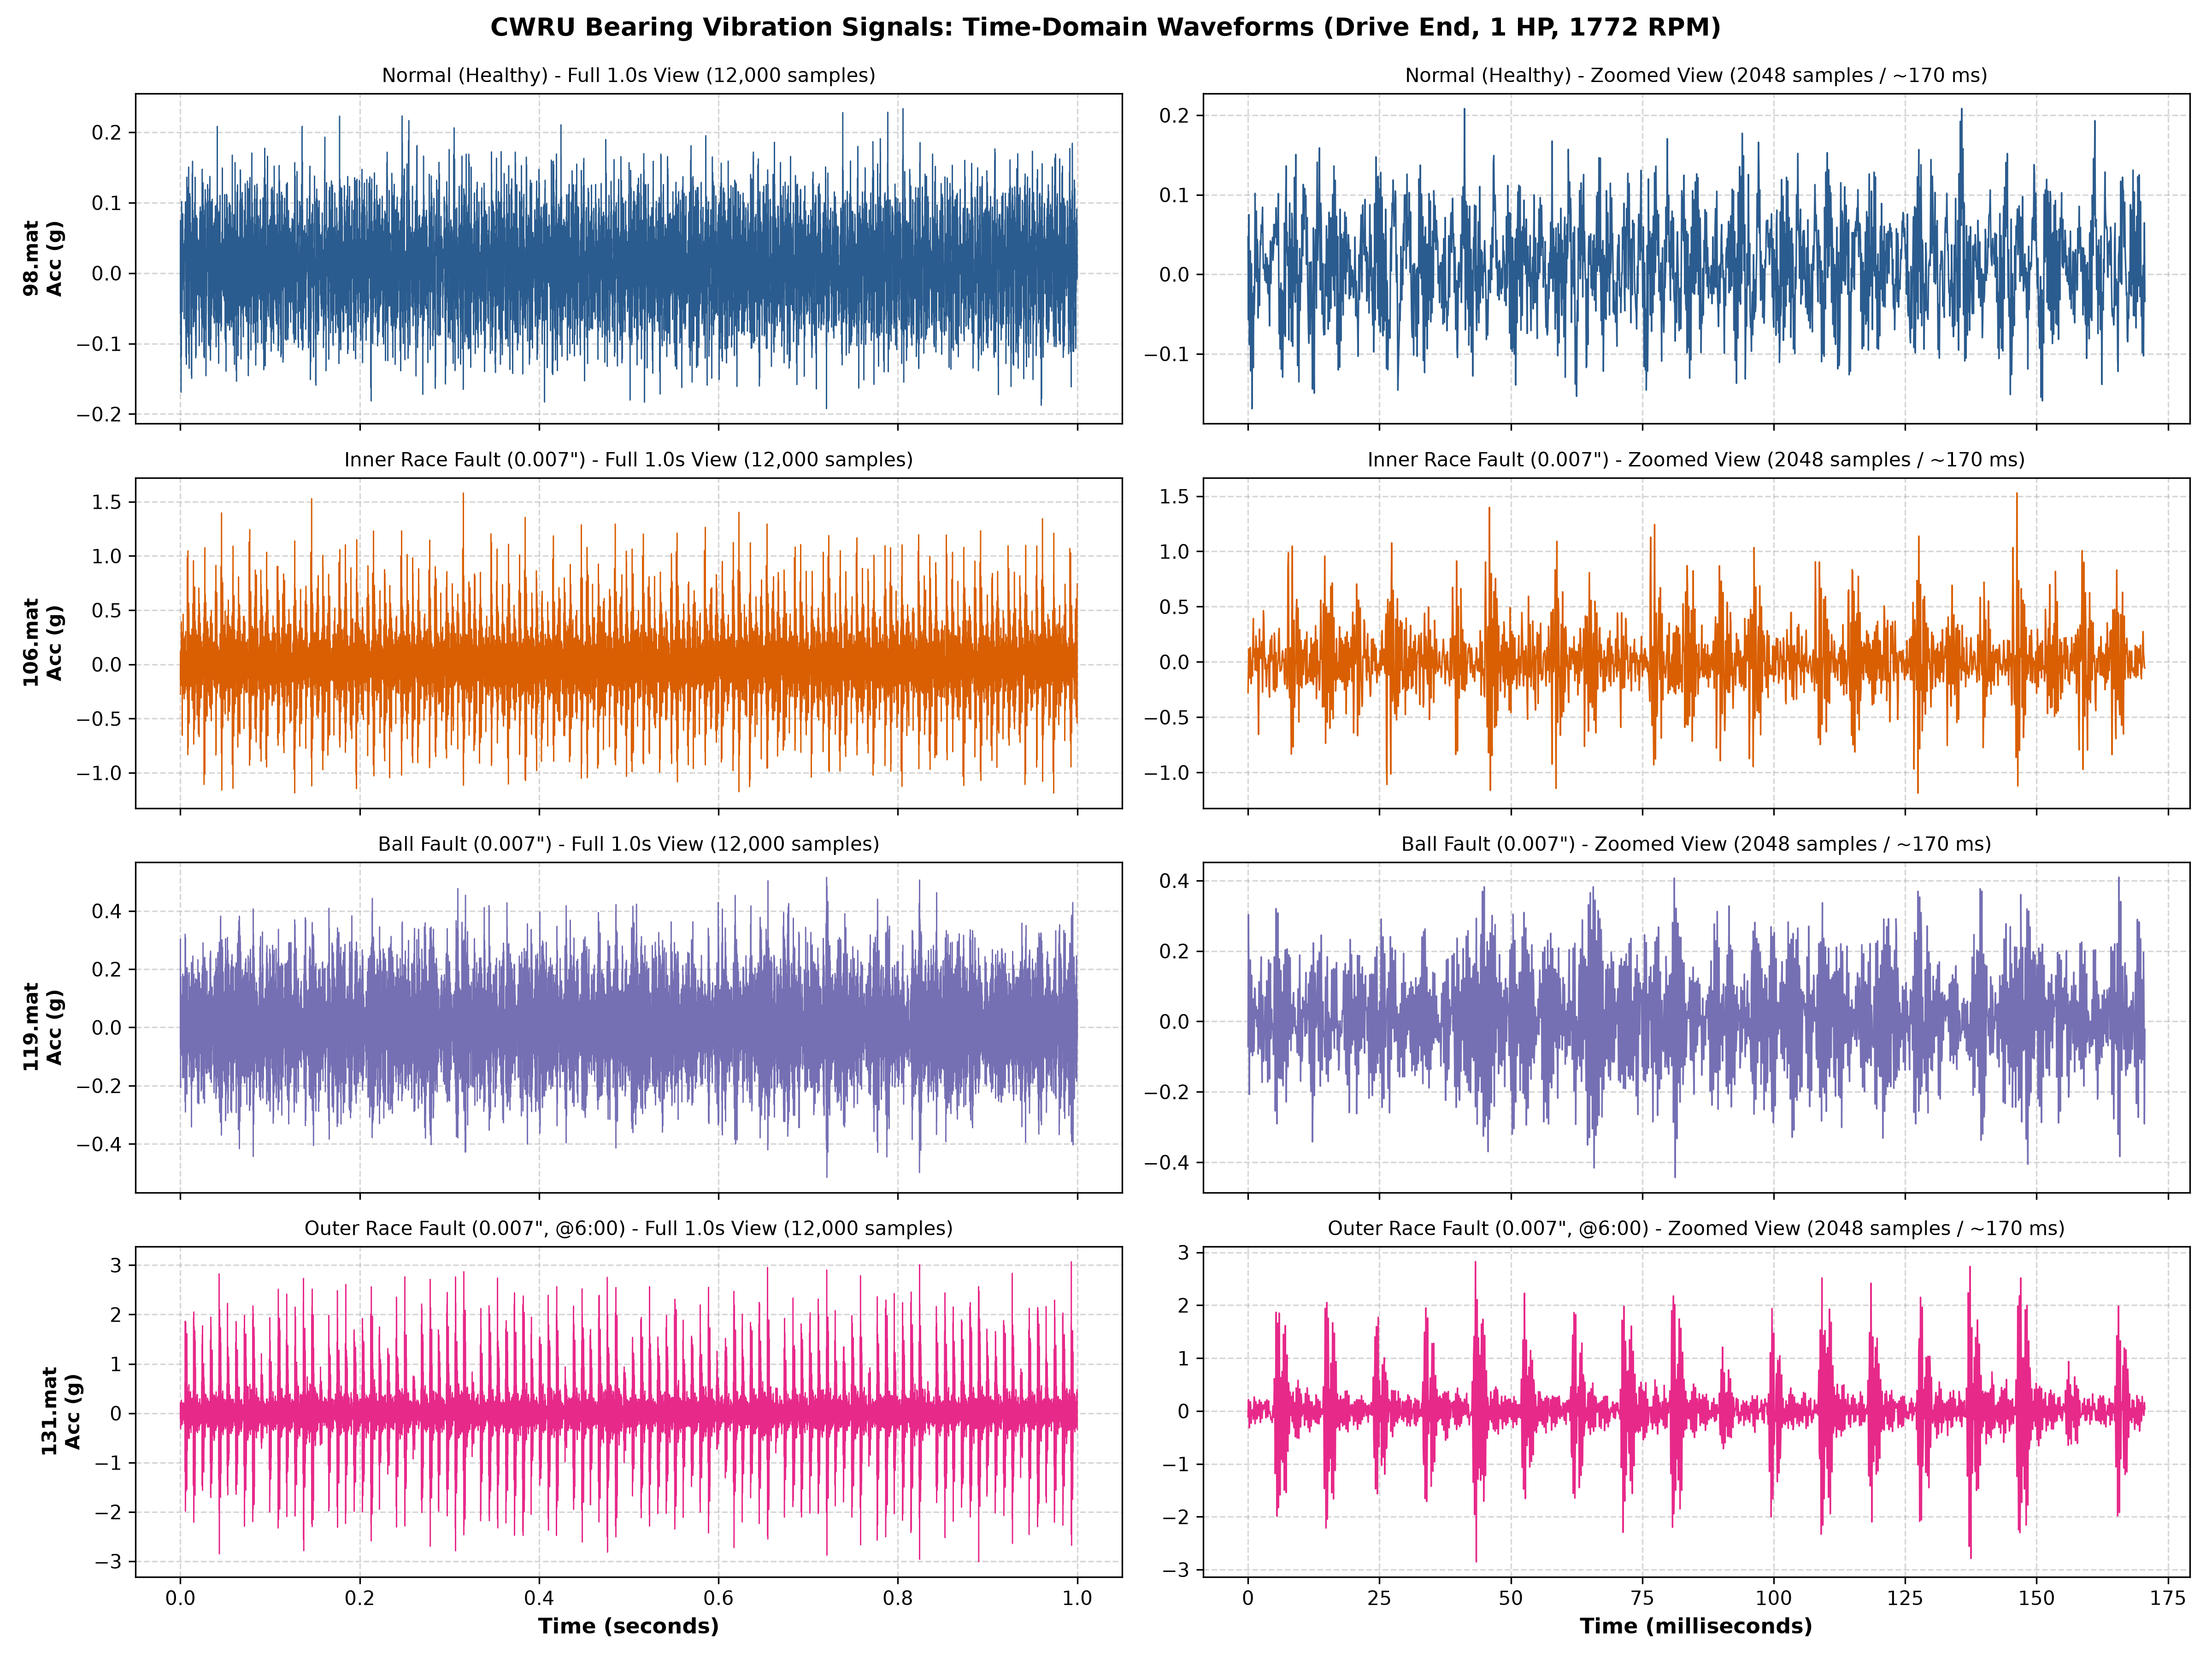

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex='col')
colors = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a']

for i, (meta, color) in enumerate(zip(files_meta, colors)):
    sig = signals[meta['label']]['12k']
    t = np.arange(len(sig)) / 12000.0
    
    # Macro 1.0 second view
    axes[i, 0].plot(t[:12000], sig[:12000], color=color, linewidth=0.6)
    axes[i, 0].set_ylabel(f"{meta['fname']}\nAcc (g)", fontsize=10, fontweight='bold')
    axes[i, 0].set_title(f"{meta['label']} - Full 1.0s View (12,000 samples)", fontsize=10)
    axes[i, 0].grid(True, linestyle='--', alpha=0.5)
    
    # Zoomed 2048 sample window (~170 ms)
    axes[i, 1].plot(t[:2048] * 1000, sig[:2048], color=color, linewidth=0.8)
    axes[i, 1].set_title(f"{meta['label']} - Zoomed View (2048 samples / ~170 ms)", fontsize=10)
    axes[i, 1].grid(True, linestyle='--', alpha=0.5)

axes[3, 0].set_xlabel('Time (seconds)', fontsize=11, fontweight='bold')
axes[3, 1].set_xlabel('Time (milliseconds)', fontsize=11, fontweight='bold')
plt.suptitle('CWRU Bearing Vibration Signals: Time-Domain Waveforms (Drive End, 1 HP, 1772 RPM)', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


## 6. Frequency-Domain Spectral Analysis (FFT) & Characteristic Fault Frequencies

### Kinematic Defect Frequencies for Drive-End SKF 6205-2RS JEM Bearing
From CWRU specifications at 1772 RPM ($f_r = 1772 / 60 = 29.533\text{ Hz}$):
- **Ball Pass Frequency Inner Ring (BPFI)**: $5.4152 \times f_r = 159.9\text{ Hz}$
- **Ball Pass Frequency Outer Ring (BPFO)**: $3.5848 \times f_r = 105.9\text{ Hz}$
- **Ball Spin Frequency (BSF)**: $2.357 \times f_r = 69.6\text{ Hz}$ ($2\times\text{BSF} \approx 139.2\text{ Hz}$)

We compute an 8,192-point Hanning-windowed FFT to achieve fine frequency resolution ($\Delta f = 1.46\text{ Hz}$).


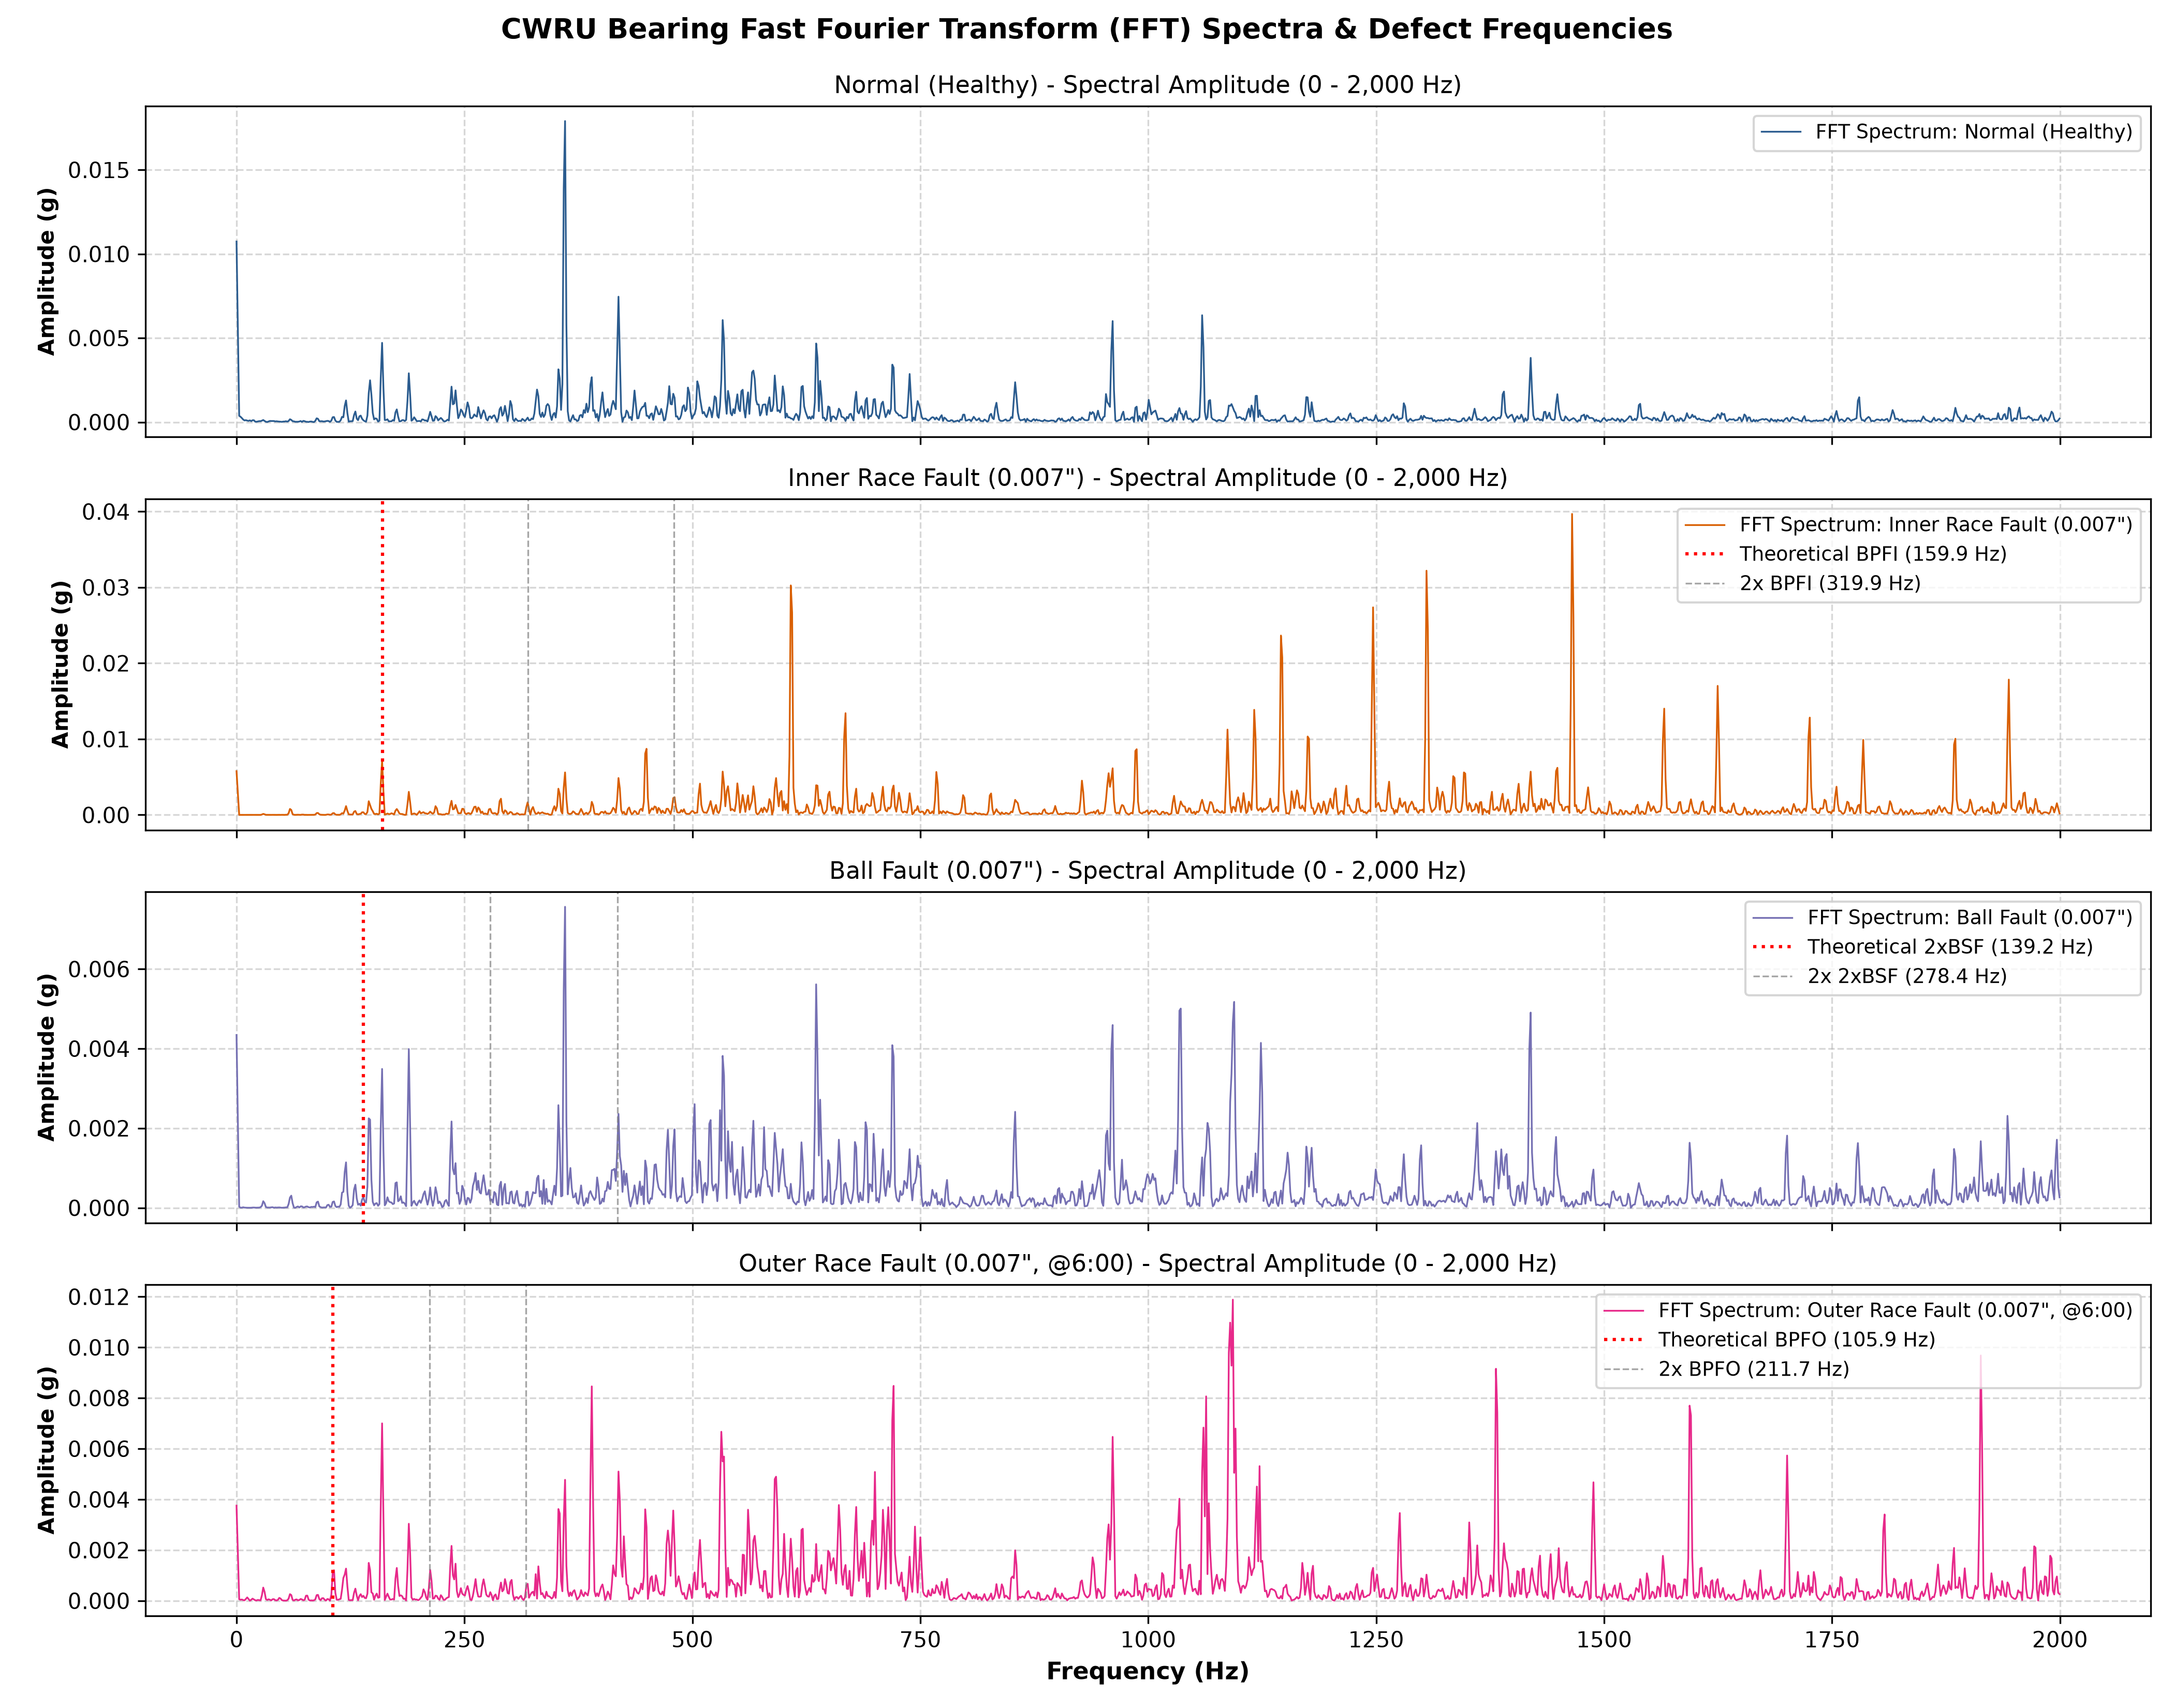

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
fr = 1772.0 / 60.0
bpfi = 5.4152 * fr
bpfo = 3.5848 * fr
bsf = 2.357 * fr

defect_freqs = {
    'Normal': None,
    'Inner Race Fault': ('BPFI', bpfi),
    'Ball Fault': ('2xBSF', 2 * bsf),
    'Outer Race Fault': ('BPFO', bpfo)
}

for i, (meta, color) in enumerate(zip(files_meta, colors)):
    sig = signals[meta['label']]['12k']
    n_fft = 8192
    segment = sig[:n_fft]
    windowed = segment * np.hanning(n_fft)
    fft_vals = np.abs(np.fft.rfft(windowed)) / (n_fft / 2)
    freqs = np.fft.rfftfreq(n_fft, 1.0 / 12000.0)
    
    mask = freqs <= 2000
    axes[i].plot(freqs[mask], fft_vals[mask], color=color, linewidth=0.8, label=f"FFT Spectrum: {meta['label']}")
    axes[i].set_ylabel('Amplitude (g)', fontsize=10, fontweight='bold')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    
    defect_info = defect_freqs[meta['label']]
    if defect_info is not None:
        name, freq_val = defect_info
        axes[i].axvline(freq_val, color='red', linestyle=':', linewidth=1.5, label=f'Theoretical {name} ({freq_val:.1f} Hz)')
        for harm in [2, 3]:
            axes[i].axvline(freq_val * harm, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, label=f'{harm}x {name} ({freq_val*harm:.1f} Hz)' if harm == 2 else None)
    
    axes[i].legend(loc='upper right', fontsize=9)
    axes[i].set_title(f"{meta['label']} - Spectral Amplitude (0 - 2,000 Hz)", fontsize=11)

axes[3].set_xlabel('Frequency (Hz)', fontsize=11, fontweight='bold')
plt.suptitle('CWRU Bearing Fast Fourier Transform (FFT) Spectra & Defect Frequencies', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


## 7. Comparative Statistical Feature Distributions


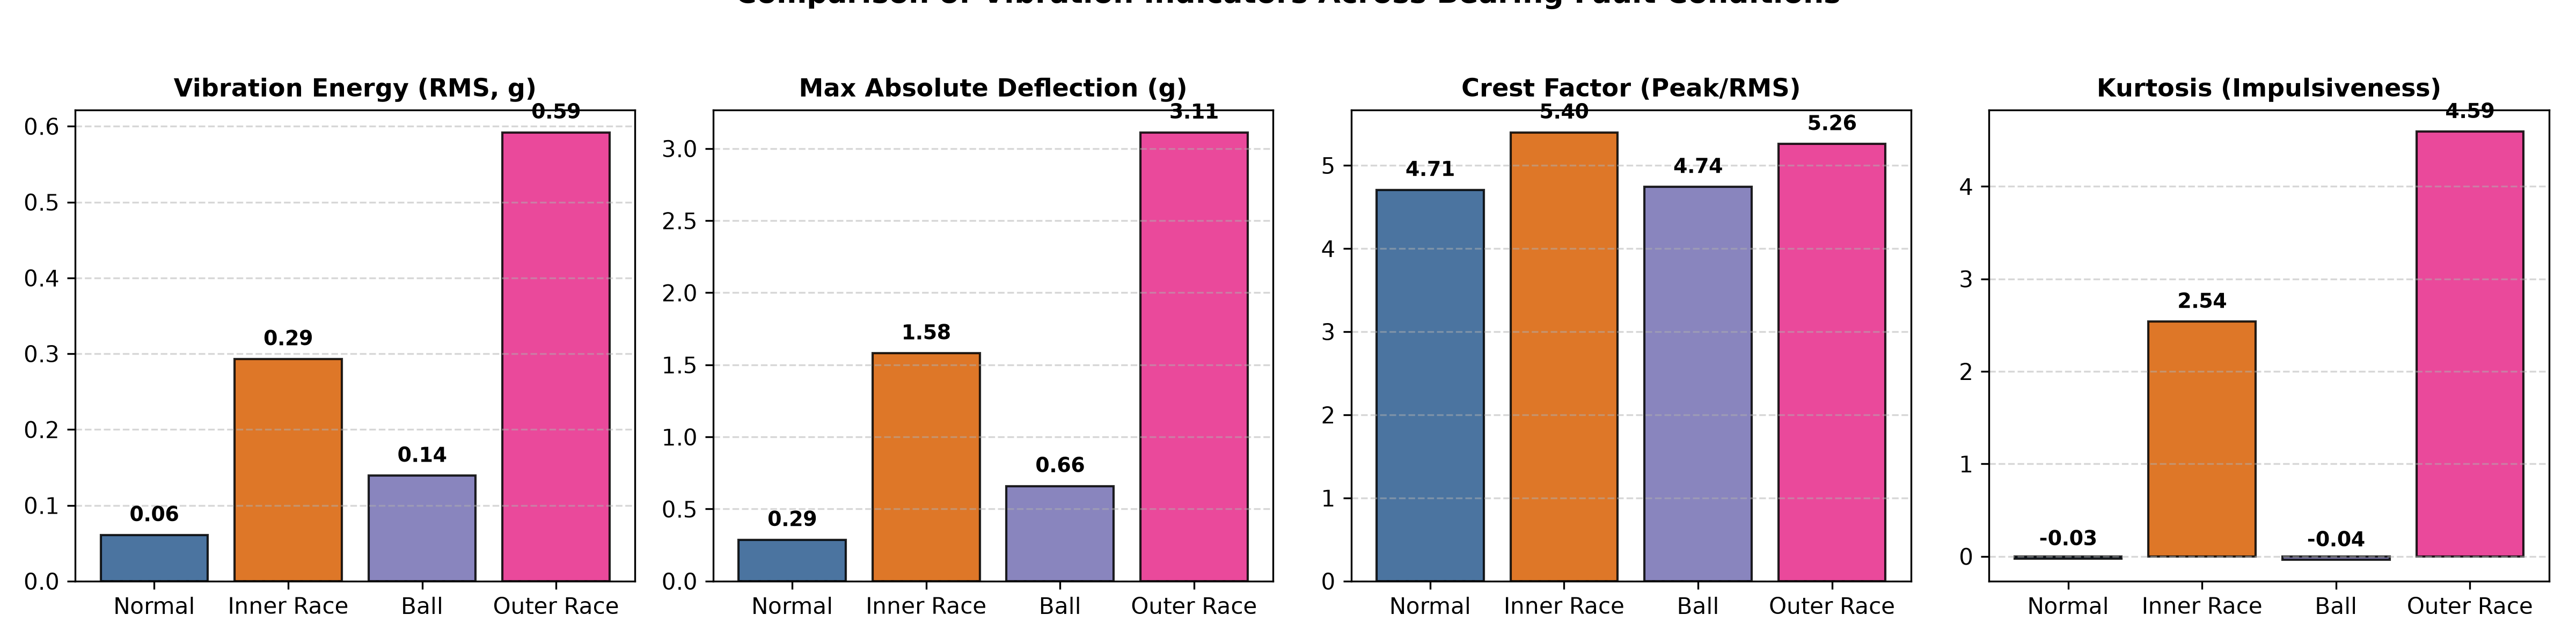

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
metrics = [('RMS (g)', 'Vibration Energy (RMS, g)'),
           ('Peak (g)', 'Max Absolute Deflection (g)'),
           ('Crest Factor', 'Crest Factor (Peak/RMS)'),
           ('Kurtosis', 'Kurtosis (Impulsiveness)')]

short_labels = ['Normal', 'Inner Race', 'Ball', 'Outer Race']
for ax, (m, title) in zip(axes, metrics):
    vals = summary_df[m].values
    bars = ax.bar(short_labels, vals, color=colors, edgecolor='black', alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 0.02 * max(vals), f'{h:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Comparison of Vibration Indicators Across Bearing Fault Conditions', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 8. Differences Between Selected Files & Critical Evaluation Considerations

### 1. Sampling Rate Discrepancy
- **Finding**: Normal baseline (`98.mat`) was recorded at **48,000 Hz** (483,903 samples, ~10.08 s), while the fault files (`106.mat`, `119.mat`, `131.mat`) were recorded at **12,000 Hz** (121,410 to 122,426 samples, ~10.12 to ~10.20 s).
- **Resolution**: Applying decimation by a factor of 4 (with an anti-aliasing Chebyshev low-pass filter) to `98.mat` aligns the normal signal to exactly **12,000 Hz** and **120,976 samples**.

### 2. Available Channels & Metadata Keys
- **Finding**: Fault files contain 4 variables (`DE_time`, `FE_time`, `BA_time`, `RPM`). The Normal file contains only 2 variables (`DE_time`, `FE_time`), with no base accelerometer (`BA_time`) or internal `RPM` variable.
- **Resolution**: Our pipeline standardizes on the **Drive End (`DE_time`)** channel, which is universally available across all classes, contains the highest signal-to-noise ratio, and directly couples to the bearing housing.

### 3. Vibration Amplitude & Class Separation
- Normal RMS: ~0.061 g
- Ball Fault RMS: ~0.139 g
- Inner Race RMS: ~0.293 g
- Outer Race RMS: ~0.592 g
This monotonic ordering directly supports both machine learning feature separability and the domain-grounded kinematic severity ordering used in `src/prioritization.py`.

### 4. Prevention of Data Leakage
- **Warning**: A very common error in predictive maintenance research is taking a continuous 10-second signal, applying sliding windows with 50% overlap, and doing a random `train_test_split`. This leaks nearly identical consecutive vibration waves between train and test sets, producing artificial 99.9% accuracy.
- **Evaluation Protocol**: We strictly enforce chronological partitioning (e.g. first 70% of continuous time for training, middle 15% for validation, last 15% for test), ensuring zero overlapping windows across splits.
